# 02 — Baseline and Candidate Design

This review turns the data-understanding conclusions into a finite, reviewable candidate design: which baselines anchor comparison, which model families are architecturally viable, which experiments are worth running, and what resource gates must clear first. Design tables come from persisted configuration; measured baseline tables come only from a validated completed full-run artifact.

## Purpose and execution status

### What this review decides

This is a design review, not an experiment run. It fixes the comparison contract, enumerates candidates, and records the gates that stand between the design and a measured result. Nothing here fits a model, generates or selects features, searches hyperparameters, tunes an operating threshold, or computes a performance number.

### Measured baselines and unmeasured candidate experiments

An earlier non-comparative smoke run exercised the baseline portfolio for workflow continuity and produced no comparative evidence. The Baseline portfolio section reads a validated full-run artifact conditionally: until a comparative OOF artifact exists, it reports *not run* with the reader's reason. A completed valid baseline run supplies measured development metrics; smoke, in-progress, stale-hash, and incomplete-OOF runs are ineligible. The candidate campaign remains not run with `null` results and unapproved families. Its general resource gates remain pending independently of the bounded baseline approval.

### Design inputs

| Input | Role |
| --- | --- |
| `configs/experiments/baselines.yaml` | Frozen prediction contract and the universal baseline portfolio |
| `configs/experiments/feature_campaign.yaml` | Model-family audit, context baselines, and the finite experiment matrix |
| `configs/resource_budget.yaml` | Candidate sizing, resource caps, approval gates, and stop rules |
| `outputs/splits/building_folds_repeated.parquet` | The persisted building-level assignment, loaded and never recreated |

**Purpose:** Resolve repository-relative design inputs, load the persisted configuration, and confirm the design-only gates are still closed.

In [1]:
import json
import re
from pathlib import Path

import polars as pl
import yaml
from IPython import get_ipython
from IPython.display import Markdown, display

from project.data.validate import compute_file_sha256
from project.experiments.baseline_review import load_baseline_review
from project.paths import ProjectPaths

paths = ProjectPaths.resolve(start=Path.cwd())
config_dir = paths.root / 'configs'
budget_path = config_dir / 'resource_budget.yaml'
campaign_path = config_dir / 'experiments' / 'feature_campaign.yaml'
baseline_path = config_dir / 'experiments' / 'baselines.yaml'
split_path = paths.splits_dir / 'building_folds_repeated.parquet'
split_metadata_path = paths.splits_dir / 'split_metadata_repeated.json'
design_inputs = {'resource budget': budget_path, 'feature campaign': campaign_path,
                 'baseline portfolio': baseline_path, 'building manifest': split_path,
                 'split metadata': split_metadata_path}
missing_inputs = [name for name, path in design_inputs.items() if not path.is_file()]
if missing_inputs:
    raise FileNotFoundError(f'Required design inputs are missing: {missing_inputs}')

def read_config(path: Path) -> dict:
    return yaml.safe_load(path.read_text(encoding='utf-8'))

def compact(text: object, limit: int = 96) -> str:
    collapsed = ' '.join(str(text).split())
    return collapsed if len(collapsed) <= limit else collapsed[: limit - 1] + '\u2026'

budget = read_config(budget_path)
campaign = read_config(campaign_path)
baseline_portfolio = read_config(baseline_path)
contract = campaign['prediction_contract']
if campaign['mode'] != 'design_only' or campaign['execution_authorized']:
    raise ValueError('The campaign must stay design-only until execution is authorized')
if budget['mode'] != 'design_only' or budget['execution_authorized']:
    raise ValueError('The resource budget must stay design-only until execution is authorized')
inherited = {'target': contract['target'], 'positive_label': contract['positive_label'],
             'primary_metric': contract['primary_metric'], 'folds': contract['folds']}
frozen = {'target': baseline_portfolio['target'], 'positive_label': baseline_portfolio['positive_label'],
          'primary_metric': baseline_portfolio['primary_metric'], 'folds': baseline_portfolio['folds']}
if inherited != frozen:
    raise ValueError('The campaign contract has drifted from the frozen baseline contract')
design_gates = pl.DataFrame([
    {'gate': 'campaign mode', 'value': str(campaign['mode'])},
    {'gate': 'campaign execution_authorized', 'value': str(campaign['execution_authorized'])},
    {'gate': 'budget mode', 'value': str(budget['mode'])},
    {'gate': 'budget execution_authorized', 'value': str(budget['execution_authorized'])},
    {'gate': 'host_preflight_status', 'value': str(budget['host_preflight_status'])},
    {'gate': 'user_approval_status', 'value': str(budget['user_approval_status'])},
    {'gate': 'target / positive label', 'value': f"{contract['target']} / {contract['positive_label']}"},
    {'gate': 'primary metric', 'value': str(contract['primary_metric'])},
    {'gate': 'guardrail metrics', 'value': ', '.join(contract['guardrails'])},
    {'gate': 'split manifest', 'value': str(contract['split_manifest'])},
    {'gate': 'development folds', 'value': str(contract['folds'])},
])
display(design_gates)

import matplotlib.pyplot as plt

_ip = get_ipython()
if _ip is not None:
    _ip.run_line_magic('matplotlib', 'inline')

from project.notebook_charts import (
    plot_comparative_count_bars,
    plot_experiment_status_bars,
    plot_fold_composition,
    render_baseline_role_tiles,
    render_family_execution_tiles,
    render_unmeasured_cap_tiles,
)


def show_figure(figure) -> None:
    display(figure)
    plt.close(figure)


gate,value
str,str
"""campaign mode""","""design_only"""
"""campaign execution_authorized""","""False"""
"""budget mode""","""design_only"""
"""budget execution_authorized""","""False"""
"""host_preflight_status""","""pending"""
…,…
"""target / positive label""","""anomaly / 1"""
"""primary metric""","""roc_auc"""
"""guardrail metrics""","""average_precision, log_loss, b…"


**Observation:** The campaign and budget both declare `design_only` with `execution_authorized` false, and both approval gates are pending. The campaign contract matches the frozen baseline contract on target, positive label, primary metric, and fold count.

**Interpretation:** The candidate design is internally consistent. A bounded non-comparative smoke run verified workflow continuity. No comparative campaign run has taken place; the separately approved three-baseline run is reviewed only if its completed OOF artifact passes validation.

**Action:** Treat candidate-campaign rows as designed-but-unmeasured and keep their gates closed. Baseline artifacts are read separately below; execution belongs to the approved scripted stage.

## Inherited decisions and deferred experiments

### Decisions carried forward unchanged

The data-understanding review fixed the parts of the problem that a candidate design must not renegotiate:

- Observed-hour point-anomaly classification keyed by `(building_id, timestamp)`; no future horizon is predicted.
- `anomaly` is the target with `1` positive; ROC-AUC is primary and ranking is preserved as a continuous score.
- `building_id` is a grouping key only, never a raw predictor.
- The persisted building assignment is authoritative; no notebook-local split is permitted.
- The `gte_*` family stays pending/blocked until provenance and prediction-time availability are demonstrated.
- No operational threshold is optimized, because false-positive and false-negative costs are unspecified.
- Labeled anomalies and unusual meter readings are preserved; nothing is silently deleted or capped.

### Deferred experiments, mapped to the finite matrix

Each deferred topic from the data-understanding hand-off is resolved into one or more concrete matrix rows, or is recorded as a justified N/A or blocked item. No topic is dropped silently.

| Deferred topic | Matrix rows | Resolution |
| --- | --- | --- |
| Cleaning | `feat_preserve_raw_vs_invalid_sentinel` | Compares native raw-value handling against a verified-invalid sentinel; no silent deletion |
| Missingness | `feat_missingness_indicators`, `feat_missingness_bitmask`, `feat_missingness_passthrough_comparison` | Indicator columns, a compact bitmask, and native-passthrough versus imputation are compared separately |
| Preprocessing | `feat_safe_calendar_numeric_transforms`, `feat_histogram_quantile`, `feat_frequency_encoding`, `feat_conditional_cross_fitted_target_encoding` | All learned transforms are fold-local; target encoding is cross-fitted to respect grouped folds |
| Outlier policy | `feat_meter_deviation_ratio` | A deviation/ratio representation expresses extreme consumption without capping or deleting rows |
| Feature families and engineering | `feat_core_vs_provided`, `feat_categorical_interactions`, `feat_group_aggregates_blocked`, `blocked_unverified_gte_family` | Provided features are compared against the core set; group aggregates and the `gte_*` family stay blocked pending point-in-time and provenance review |
| PCA candidacy | `dim_pca_vs_passthrough` | Projection is compared against passthrough for distance-based families rather than assumed helpful |
| Imbalance | `regime_natural_vs_class_weighted` | Class weighting is compared against the natural distribution with the ranking metric kept primary |
| Feature selection | `dim_fold_local_selector_vs_passthrough`, `dim_semantic_block_drop` | Selection is fitted per training fold; block drops isolate which semantic group carries signal |
| Same-family tuning | `regime_same_family_hpo_vs_default` | A search is scoped inside one family so tuning gain is separable from family choice |
| Operating threshold | none — justified N/A | Costs are unspecified, so no threshold row exists; adding one would invent a decision boundary without a cost basis |
| Identifier mining | `prohibited_opaque_building_id_digit_extraction` | Explicitly prohibited: digits of an opaque identifier carry no defensible meaning for unseen buildings |

## Persisted split verification

The assignment is read from `outputs/splits/building_folds_repeated.parquet` exactly as produced; this notebook never reshuffles, re-stratifies, or falls back to a row-wise split. One manifest row is one building, which is what makes whole-building separation checkable: a building can appear in only one partition, so no hour of a building can sit on both sides of a fold boundary.

The expected shape is an isolated vault plus four building-held-out development folds. Verification below is structural and reads only the manifest and its metadata.

**Purpose:** Load the persisted manifest, confirm one row per building, verify whole-building separation across every partition, and report the vault and development-fold composition.

check,observed
str,i64
"""unique training buildings""",200
"""unique development buildings""",160
"""fixed vault buildings""",40
"""manifest assignments""",600
"""development fold assignments""",12
"""partitions sharing a building …",0


repeat,seed,split,fold,buildings,rows,anomaly_rows,normal_rows
i64,i64,str,i64,u32,i64,i64,i64
0,42,"""dev""",0,40,350908,7313,343595
0,42,"""dev""",1,40,350467,7518,342949
0,42,"""dev""",2,40,348223,7644,340579
0,42,"""dev""",3,40,350033,7581,342452
0,42,"""vault""",null,40,349863,7240,342623
…,…,…,…,…,…,…,…
2,44,"""dev""",0,40,350152,7279,342873
2,44,"""dev""",1,40,350647,7452,343195
2,44,"""dev""",2,40,349330,7738,341592


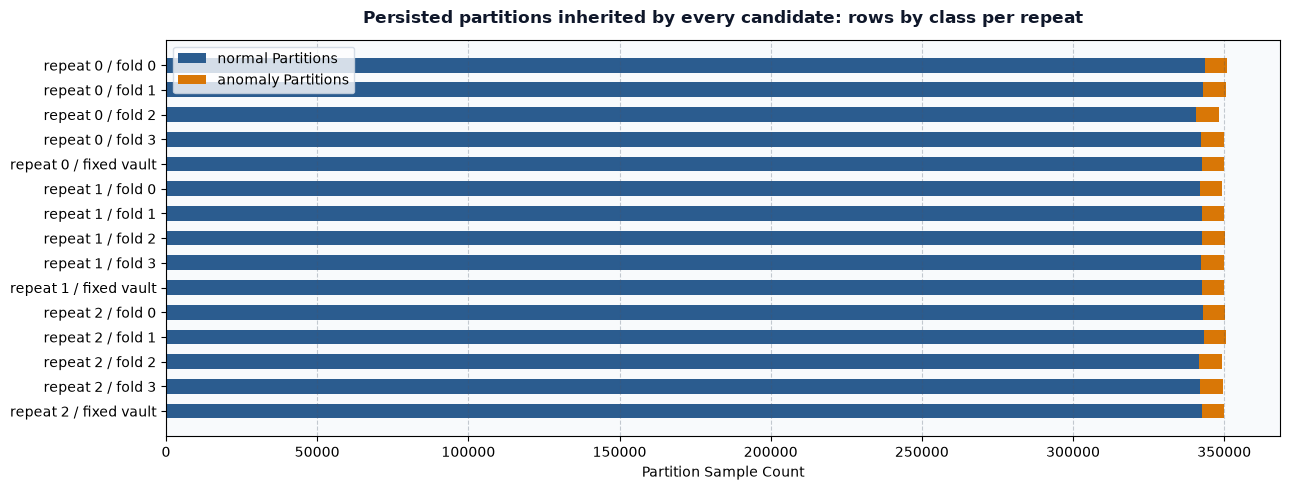

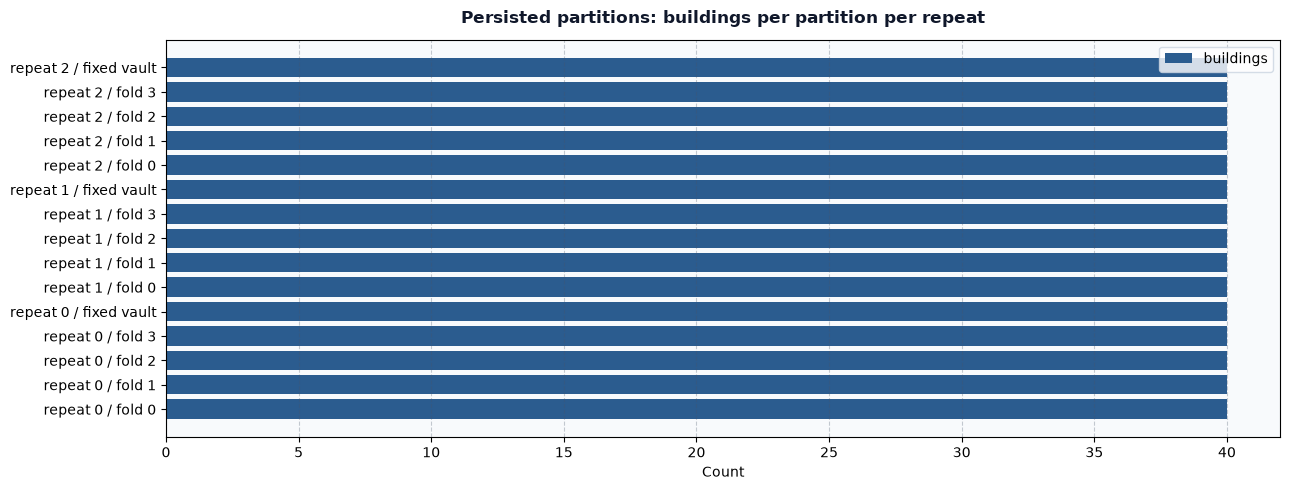

In [2]:
def validate_repeated_manifest(manifest, metadata, original=None):
    required = {'repeat', 'seed', 'building_id', 'split', 'fold', 'row_count', 'anomaly_count', 'normal_count'}
    if not required.issubset(manifest.columns):
        raise ValueError('Repeated manifest lacks assignment or support columns')
    if (metadata.get('repeats'), metadata.get('n_dev_folds'), metadata.get('split_seeds')) != (3, 4, [42, 43, 44]):
        raise ValueError('Expected the predeclared 4-fold x 3-repeat contract')
    if manifest.height != 600 or manifest.select(['repeat', 'building_id']).is_duplicated().any():
        raise ValueError('Expected 600 unique (repeat, building_id) assignments')
    if any(manifest[c].null_count() for c in required - {'fold'}):
        raise ValueError('Assignment and support fields must be non-null')
    if set(manifest['repeat']) != {0, 1, 2}:
        raise ValueError('Expected repeats 0, 1, 2')
    vault_ids = set(metadata.get('vault_building_ids', []))
    if len(vault_ids) != 40:
        raise ValueError('Vault metadata must specify exactly 40 fixed vault buildings')
    if original is not None:
        if original.height != 200 or original['building_id'].n_unique() != 200:
            raise ValueError('Original manifest must cover 200 unique buildings')
        old_vault = set(original.filter(pl.col('split') == 'vault')['building_id'])
        if len(old_vault) != 40 or old_vault != vault_ids:
            raise ValueError('Vault metadata differs from the original fixed vault')
        support = ['building_id', 'split', 'row_count', 'anomaly_count', 'normal_count']
        support += [c for c in ('anomaly_prevalence',) if c in original.columns]
    signatures = set()
    for repeat, seed in enumerate(metadata['split_seeds']):
        part = manifest.filter(pl.col('repeat') == repeat)
        if part.height != 200 or set(part['seed']) != {seed}:
            raise ValueError('Per-repeat population or split seed differs')
        if original is not None and not part.select(support).sort('building_id').equals(original.select(support).sort('building_id')):
            raise ValueError('Fixed population, vault, or support changed across repeats')
        vault = part.filter(pl.col('split') == 'vault')
        dev = part.filter(pl.col('split') == 'dev')
        if vault['fold'].null_count() != 40 or dev.height != 160 or dev['fold'].null_count() or set(dev['fold']) != {0, 1, 2, 3}:
            raise ValueError('Invalid fixed vault or development fold assignment')
        members = [set(dev.filter(pl.col('fold') == f)['building_id']) for f in range(4)]
        if any(len(group) != 40 for group in members):
            raise ValueError('Each development fold must contain 40 buildings')
        partitions = members + [set(vault['building_id'])]
        if any(left & right for i, left in enumerate(partitions) for right in partitions[i + 1:]):
            raise ValueError('Groups overlap within a repeat')
        signature = frozenset(frozenset(group) for group in members)
        if signature in signatures:
            raise ValueError('Repeated partitions are copied or merely fold-relabeled')
        signatures.add(signature)
    summary = (manifest.group_by(['repeat', 'seed', 'split', 'fold'])
        .agg(pl.len().alias('buildings'), pl.col('row_count').sum().alias('rows'),
             pl.col('anomaly_count').sum().alias('anomaly_rows'), pl.col('normal_count').sum().alias('normal_rows'))
        .sort(['repeat', 'split', 'fold'], nulls_last=True))
    if summary.filter((pl.col('anomaly_rows') <= 0) | (pl.col('normal_rows') <= 0)).height:
        raise ValueError('Every partition must retain both target classes')
    return summary

split_metadata = json.loads(split_metadata_path.read_text(encoding='utf-8'))
manifest_hash = compute_file_sha256(split_path)
if manifest_hash != split_metadata['artifacts']['building_folds_sha256'] or manifest_hash != split_metadata['family_sha256']:
    raise ValueError('Repeated master manifest hash is stale')
original_split_path = paths.splits_dir / 'building_folds.parquet'
original_manifest = pl.read_parquet(original_split_path) if original_split_path.exists() else None
if (baseline_portfolio['repeats'], baseline_portfolio['folds'], baseline_portfolio['split_seeds'], baseline_portfolio['split_manifest']) != (3, 4, split_metadata['split_seeds'], 'outputs/splits/building_folds_repeated.parquet'):
    raise ValueError('Repeated split differs from the frozen baseline config')
split_manifest = pl.read_parquet(split_path)
partition_summary = validate_repeated_manifest(split_manifest, split_metadata, original_manifest)
separation_review = pl.DataFrame([
    {'check': 'unique training buildings', 'observed': 200},
    {'check': 'unique development buildings', 'observed': 160},
    {'check': 'fixed vault buildings', 'observed': 40},
    {'check': 'manifest assignments', 'observed': split_manifest.height},
    {'check': 'development fold assignments', 'observed': 12},
    {'check': 'partitions sharing a building within each repeat', 'observed': 0},
])
display(separation_review)
display(partition_summary)

show_figure(plot_fold_composition(
    {(f"repeat {row['repeat']} / fold {row['fold']}" if row['split'] == 'dev' else f"repeat {row['repeat']} / fixed vault"):
        {'normal': int(row['normal_rows']), 'anomaly': int(row['anomaly_rows'])}
     for row in partition_summary.to_dicts()},
    'Persisted partitions inherited by every candidate: rows by class per repeat'))
show_figure(plot_comparative_count_bars(
    {(f"repeat {row['repeat']} / fold {row['fold']}" if row['split'] == 'dev' else f"repeat {row['repeat']} / fixed vault"):
        {'buildings': int(row['buildings'])} for row in partition_summary.to_dicts()},
    'Persisted partitions: buildings per partition per repeat'))


**Observation:** The manifest holds one row per building, the vault is isolated, the development folds match the contracted fold count, no two partitions share a building, and every partition retains both classes.

**Interpretation:** Whole-building separation holds, so a validation fold contains only buildings the training folds never saw. That matches the unseen-building evaluation unit and is what makes any later comparison meaningful.

**Action:** Every candidate below is evaluated against this exact manifest. A row-wise or freshly generated split would silently change the question being asked and is forbidden by the stop rules.

## Baseline portfolio

### Universal baselines

Three universal baselines anchor the comparison, defined in `configs/experiments/baselines.yaml`:

- `dummy_prior` — predicts the training prior. It calibrates what "no signal" looks like under this metric and prevalence.
- `logistic_l2` — an L2-regularised linear model. It establishes how much of the signal is linearly accessible.
- `hist_gradient_boosting` — an untuned histogram gradient-boosting model. It shows what a standard non-linear learner reaches before any tuning.

These are anchors, not competitors. Their value is that they make any later gain interpretable: a candidate that cannot separate itself from the prior baseline has not demonstrated anything, and a candidate that barely moves past the linear model has not justified its extra complexity.

### Context baselines

Beyond the universal set, four context anchors are audited in the campaign configuration. Each carries a recorded status and justification rather than being quietly omitted:

- `business_incumbent` — pending input; no incumbent detector performance has been supplied, so the anchor cannot be stated.
- `temporal_naive` — N/A on architectural grounds, not resource grounds: held-out folds contain unseen buildings with no label history, so a per-building history predictor has nothing to read at prediction time.
- `grouped_hierarchical` — pending; whether point-in-time-safe building-level aggregates can be built without leakage has not been confirmed, so it is held open rather than dismissed.
- `current_champion` — frozen pending comparison in the configuration. A new nominal baseline reference from a validated full run is separate from this context anchor and is not a production winner.

**Purpose:** Read validated baseline evidence conditionally, render pooled metrics and their references before runtime findings and full evidence tables, and retain the frozen context-anchor audit.

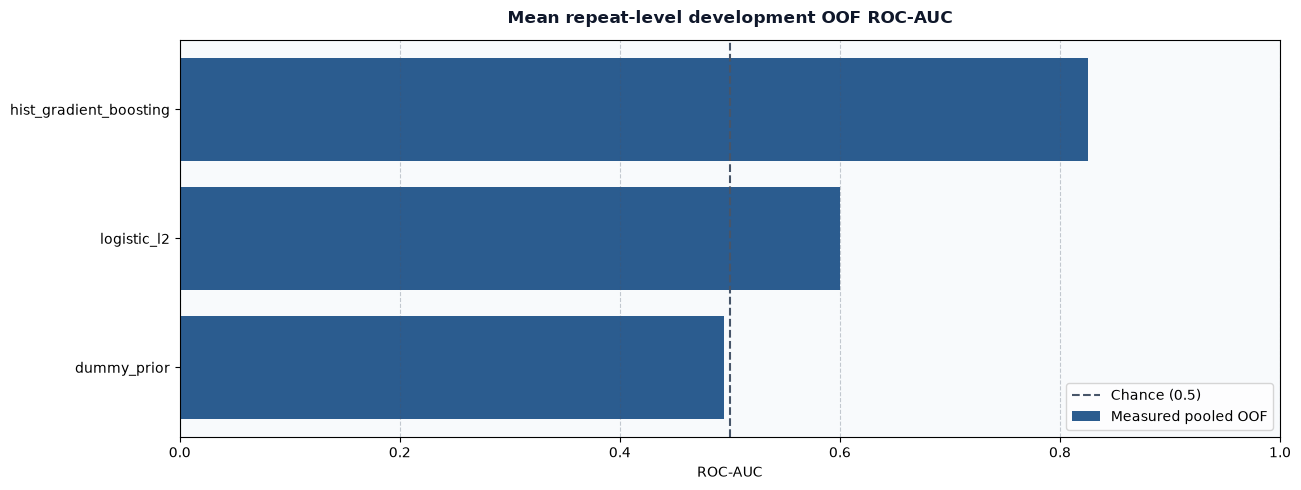

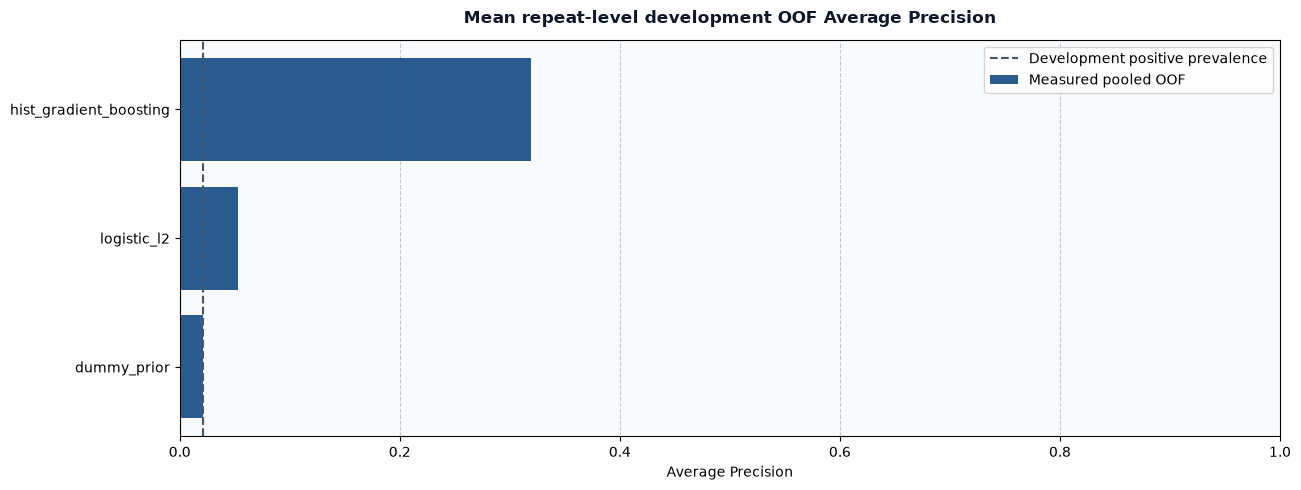

**Observation:** Validated run `20261001T194124Z-b9e01719` covers 1,399,631 development rows and 160 buildings across 4 folds. Nominal reference `hist_gradient_boosting` has pooled ROC-AUC 0.825648 and Average Precision 0.319046; development positive prevalence is 0.021474.

Its log loss 0.164360 is worse than `dummy_prior` 0.103726 and `logistic_l2` 0.106758 (lower is better). Worst reference log loss: repeat 0 / fold 1, 0.353887. Its Brier score 0.036465 is worse than `dummy_prior` 0.021013 and `logistic_l2` 0.020843 (lower is better). Worst reference Brier score: repeat 0 / fold 1, 0.074182. Dummy per-fold ROC-AUC is 0.5, while pooled ROC-AUC is 0.494340: different training priors between folds yield different constant scores. This does not imply a bug or justify score inversion.

**Interpretation:** The nominal reference has the highest validated pooled ROC-AUC; this is not statistically significant promotion or a production winner. Four folds across three split seeds (estimator seed 42, split seeds [42, 43, 44], 12 dependent fits per candidate) yield descriptive spread. The recorded fold and repeat standard deviation is not a confidence interval. Log loss and Brier score are guardrails, not evidence of causality. The frozen pending current_champion context anchor remains distinct from this nominal baseline reference.

**Action:** Retain all three baselines, inspect every fold and fit cost below, and use this reference for future authorized comparisons. Probability-quality investigation and a calibration hypothesis are future work, not run. No operational decision cutoff is selected because false-positive/false-negative costs are unknown. FE, PCA, FS and HPO remain not run; candidate-campaign results remain null and optional families unapproved.

candidate_id,model_family,roc_auc,average_precision,log_loss,brier_score,fold_roc_auc_mean,fold_roc_auc_std,fit_wall_seconds,repeat_roc_auc_mean,repeat_roc_auc_std
str,str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""dummy_prior""","""dummy""",0.49434,0.021188,0.103726,0.021013,0.5,0.0,3.72832,0.49434,0.000963
"""logistic_l2""","""linear_model""",0.600079,0.052523,0.106758,0.020843,0.601709,0.026593,153.516829,0.600079,0.010204
"""hist_gradient_boosting""","""ensemble_gbdt""",0.825648,0.319046,0.16436,0.036465,0.826974,0.03754,217.759749,0.825648,0.012126


candidate_id,repeat,split_seed,roc_auc,average_precision,log_loss,brier_score
str,i64,i64,f64,f64,f64,f64
"""dummy_prior""",0,42,0.494734,0.021198,0.103725,0.021013
"""logistic_l2""",0,42,0.595228,0.069193,0.109076,0.020711
"""hist_gradient_boosting""",0,42,0.818826,0.208546,0.234859,0.049023
"""dummy_prior""",1,43,0.495044,0.021226,0.103725,0.021013
"""logistic_l2""",1,43,0.593206,0.04709,0.105554,0.020901
"""hist_gradient_boosting""",1,43,0.818469,0.354498,0.122436,0.027164
"""dummy_prior""",2,44,0.493243,0.021139,0.103727,0.021013
"""logistic_l2""",2,44,0.611804,0.041285,0.105643,0.020916
"""hist_gradient_boosting""",2,44,0.839648,0.394093,0.135787,0.033207


candidate_id,repeat,split_seed,fold,roc_auc,average_precision,log_loss,brier_score
str,i64,i64,i64,f64,f64,f64,f64
"""dummy_prior""",0,42,0,0.5,0.02084,0.101308,0.020407
"""dummy_prior""",0,42,1,0.5,0.021451,0.103635,0.020991
"""dummy_prior""",0,42,2,0.5,0.021951,0.105549,0.02147
"""dummy_prior""",0,42,3,0.5,0.021658,0.104425,0.021189
"""logistic_l2""",0,42,0,0.595713,0.050387,0.098897,0.02035
"""logistic_l2""",0,42,1,0.574992,0.027964,0.102312,0.020981
"""logistic_l2""",0,42,2,0.564874,0.028672,0.104432,0.021435
"""logistic_l2""",0,42,3,0.638413,0.190919,0.130674,0.020084
"""hist_gradient_boosting""",0,42,0,0.853206,0.237335,0.184198,0.035566


field,value
str,str
"""run_id""","""20261001T194124Z-b9e01719"""
"""run_path""","""outputs/runs/20261001T194124Z-b9e01719"""
"""development_rows""","""1399631"""
"""development_buildings""","""160"""
"""fold_count""","""4"""
"""positive_prevalence""","""0.02147423142242491"""
"""reference_candidate_id""","""hist_gradient_boosting"""
"""resources""","""{'candidate_fit_wall_time_seconds': {'dummy_prior': 3.7283201449754415, 'hist_gradient_boosting': 217.75974939603475, 'logistic_l2': 153.51682854798855}, 'elapsed_seconds': 414.342, 'fold_ids': [0, 1, 2, 3], 'memory_note': 'Python-traced memory excludes some native-library allocations; process peak RSS is included when the platform exposes resource.getrusage.', 'mode': 'full', 'model_fit_count': 36, 'non_comparative': False, 'process_peak_rss_mb': 2721.938, 'python_traced_peak_memory_mb': 436.582, 'repeat_count': 3, 'repeat_ids': [0, 1, 2], 'run_id': '20261001T194124Z-b9e01719', 'split_seeds': [42, 43, 44], 'execution_guard': {'run_id': '20261001T194124Z-b9e01719', 'status': 'completed', 'reason': None, 'elapsed_seconds': 416.103286, 'peak_process_tree_rss_bytes': 2850586624, 'cpu_threads': 4, 'max_wall_seconds': 2700, 'max_rss_bytes': None, 'rss_limit_enforced': False, 'poll_seconds': 0.05, 'worker_exitcode': 0}, 'execution_budget': {'approval_status': 'approved', 'cpu_threads': 4, 'fold_ids': [0, 1, 2, 3], 'max_rss_bytes': None, 'max_wall_seconds': 2700, 'models': ['dummy_prior', 'logistic_l2', 'hist_gradient_boosting'], 'planned_fits': 36, 'preflight': {'available_memory_mib': 6818, 'free_disk_gb': 240, 'logical_cpu_threads': 20, 'total_memory_mib': 15683}, 'repeat_ids': [0, 1, 2], 'resource_status': 'approved', 'rss_limit_enforced': False, 'scope': 'baseline_only', 'seed': 42, 'split_seeds': [42, 43, 44]}}"""


baseline,model_family,recipe_id,role,result_status
str,str,str,str,str
"""dummy_prior""","""dummy""","""recipe_dummy_prior""","""reference anchor""","""completed — validated full-run…"
"""logistic_l2""","""linear_model""","""recipe_logistic_l2""","""reference anchor""","""completed — validated full-run…"
"""hist_gradient_boosting""","""ensemble_gbdt""","""recipe_hist_gradient_boosting""","""reference anchor""","""completed — validated full-run…"


context_baseline,status,applicable,justification,comparison_artifact
str,str,str,str,str
"""business_incumbent""","""pending_input""","""not asserted""","""Incumbent system details (prec…","""none — not run"""
"""temporal_naive""","""N/A""","""False""","""Unseen buildings in held-out f…","""none — not run"""
"""grouped_hierarchical""","""pending""","""not asserted""","""Whether point-in-time-safe bui…","""none — not run"""
"""current_champion""","""pending_comparison""","""not asserted""","""The earlier baseline smoke pro…","""none — not run"""


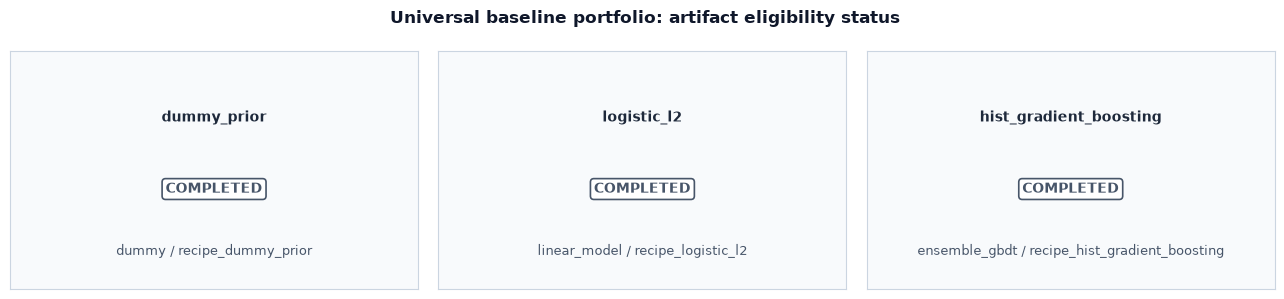

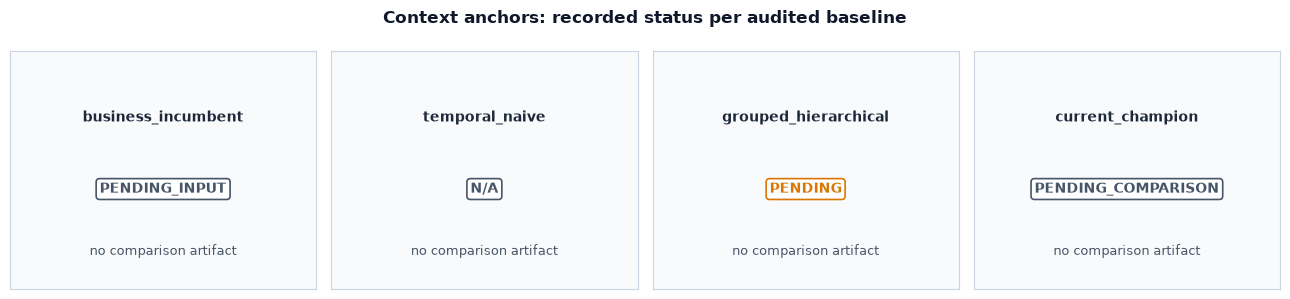

In [3]:
def render_baseline_review(root):
    review = load_baseline_review(root)
    if review['status'] != 'completed':
        display(Markdown(
            f"**Observation:** Baseline results: not run. {review['reason']}\n\n"
            '**Interpretation:** No completed valid full-run OOF evidence is available; '
            'the non-comparative smoke is ineligible.\n\n'
            '**Action:** Complete the approved scripted baseline run before comparison. '
            'FE, PCA, FS and HPO remain not run.'))
        return review
    metrics = review['metrics']
    for metric, title, xlabel, reference, label in (
        ('roc_auc', 'Mean repeat-level development OOF ROC-AUC', 'ROC-AUC', 0.5, 'Chance (0.5)'),
        ('average_precision', 'Mean repeat-level development OOF Average Precision',
         'Average Precision', review['positive_prevalence'], 'Development positive prevalence'),
    ):
        figure = plot_comparative_count_bars(
            {row['candidate_id']: {'Measured pooled OOF': float(row[metric])}
             for row in metrics.to_dicts()}, title=title, xlabel=xlabel)
        figure.axes[0].set_xlim(0, 1)
        figure.axes[0].axvline(reference, linestyle='--', color='#475569', label=label)
        figure.axes[0].legend()
        show_figure(figure)
    reference_id = review['reference_candidate_id']
    reference_row = next(row for row in metrics.to_dicts()
                         if row['candidate_id'] == reference_id)
    guardrail_findings = []
    for metric, label in (('log_loss', 'log loss'), ('brier_score', 'Brier score')):
        comparisons = [
            f"`{row['candidate_id']}` {row[metric]:.6f}"
            for row in metrics.to_dicts()
            if row['candidate_id'] != reference_id and row[metric] < reference_row[metric]
        ]
        if comparisons:
            guardrail_findings.append(
                f"Its {label} {reference_row[metric]:.6f} is worse than "
                + ' and '.join(comparisons) + ' (lower is better).')
        folds = review['fold_metrics'].filter(pl.col('candidate_id') == reference_id)
        if metric in folds.columns and not folds.is_empty():
            worst = max(folds.to_dicts(), key=lambda row: row[metric])
            repeat_prefix = f"repeat {worst['repeat']} / " if 'repeat' in worst else ""
            guardrail_findings.append(
                f"Worst reference {label}: {repeat_prefix}fold {worst['fold']}, {worst[metric]:.6f}.")
    dummy_rows = metrics.filter(pl.col('candidate_id') == 'dummy_prior').to_dicts()
    dummy_folds = review['fold_metrics'].filter(pl.col('candidate_id') == 'dummy_prior')
    if dummy_rows and not dummy_folds.is_empty() and all(
        value == 0.5 for value in dummy_folds['roc_auc'].to_list()
    ):
        guardrail_findings.append(
            f"Dummy per-fold ROC-AUC is 0.5, while pooled ROC-AUC is {dummy_rows[0]['roc_auc']:.6f}: "
            'different training priors between folds yield different constant scores. '
            'This does not imply a bug or justify score inversion.')
    guardrail_text = ' '.join(guardrail_findings)
    display(Markdown(
        f"**Observation:** Validated run `{review['run_id']}` covers "
        f"{review['development_rows']:,} development rows and "
        f"{review['development_buildings']:,} buildings across {review['fold_count']} folds. "
        f"Nominal reference `{reference_id}` has pooled ROC-AUC {reference_row['roc_auc']:.6f} "
        f"and Average Precision {reference_row['average_precision']:.6f}; development "
        f"positive prevalence is {review['positive_prevalence']:.6f}.\n\n"
        f'{guardrail_text}\n\n'
        '**Interpretation:** The nominal reference has the highest validated pooled ROC-AUC; '
        'this is not statistically significant promotion or a production winner. Four folds across three '
        'split seeds (estimator seed 42, split seeds [42, 43, 44], 12 dependent fits per candidate) '
        'yield descriptive spread. The recorded fold and repeat standard deviation '
        'is not a confidence interval. Log loss and Brier score are guardrails, '
        'not evidence of causality. The frozen pending current_champion context anchor '
        'remains distinct from this nominal baseline reference.\n\n'
        '**Action:** Retain all three baselines, inspect every fold and fit cost below, '
        'and use this reference for future authorized comparisons. Probability-quality '
        'investigation and a calibration hypothesis are future work, not run. No operational decision cutoff '
        'is selected because false-positive/false-negative costs are unknown. FE, PCA, FS and HPO '
        'remain not run; candidate-campaign results remain null and optional families unapproved.'))
    with pl.Config(tbl_rows=-1, tbl_cols=-1, fmt_str_lengths=10000):
        display(metrics)
        display(review['repeat_metrics'])
        display(review['fold_metrics'])
        display(pl.DataFrame([
            {'field': key, 'value': str(review[key])}
            for key in ('run_id', 'run_path', 'development_rows', 'development_buildings',
                        'fold_count', 'positive_prevalence', 'reference_candidate_id', 'resources')
        ]))
    return review

baseline_review = render_baseline_review(paths.root)
universal_baselines = pl.DataFrame([
    {'baseline': name,
     'model_family': str(spec['model_family']),
     'recipe_id': str(spec['recipe_id']),
     'role': 'reference anchor',
     'result_status': ('completed — validated full-run artifact'
                       if baseline_review['status'] == 'completed' else 'not run — pending execution')}
    for name, spec in baseline_portfolio['models'].items()
])
display(universal_baselines)
context_baselines = pl.DataFrame([
    {'context_baseline': name,
     'status': str(spec.get('status')),
     'applicable': 'not asserted' if spec.get('applicable') is None else str(spec['applicable']),
     'justification': compact(re.sub(
         r'^\w+\s+\d+\b', 'The earlier baseline smoke',
         spec.get('rejection_reason') or spec.get('rationale')), 120),
     'comparison_artifact': 'none \u2014 not run'}
    for name, spec in campaign['context_baselines'].items()
])
display(context_baselines)
unjustified = [
    name for name, spec in campaign['context_baselines'].items()
    if not (spec.get('rejection_reason') or spec.get('rationale'))
]
if unjustified:
    raise ValueError(f'Every context baseline must carry a recorded justification: {unjustified}')

show_figure(render_baseline_role_tiles(
    [{'header': row['baseline'], 'status': baseline_review['status'].replace('_', ' ').upper(),
      'meta': f"{row['model_family']} / {row['recipe_id']}"}
     for row in universal_baselines.to_dicts()],
    'Universal baseline portfolio: artifact eligibility status'))
show_figure(render_baseline_role_tiles(
    [{'header': row['context_baseline'], 'status': str(row['status']).upper(),
      'meta': 'no comparison artifact'}
     for row in context_baselines.to_dicts()],
    'Context anchors: recorded status per audited baseline'))


**Observation:** All three universal baselines have recipe identifiers; their outcomes are reported above only from eligible completed artifacts. All four context anchors carry their frozen configuration statuses and justifications.

**Interpretation:** The only anchor ruled out on structural grounds is the temporal-naive one, and its reason is a property of the evaluation design rather than a shortage of compute or data. The remaining anchors are open questions with named blockers, which is a weaker claim than N/A and is the honest one here.

**Action:** Supply incumbent detector performance if an incumbent exists, and resolve the grouped/hierarchical question through point-in-time verification before treating it as either usable or inapplicable.

## Model-family audit

Eight model families are audited in `configs/experiments/feature_campaign.yaml` under `model_family_audit`. The audit separates two questions that are easy to conflate:

- **Is the family architecturally applicable?** Can it consume this feature shape and respect the building-grouped evaluation without a structural violation?
- **Is the family currently runnable?** Are the dependency and compute prerequisites approved?

### Why `blocked_unapproved_compute` is not a false N/A

A family marked `applicable: true` with `execution_status: blocked_unapproved_compute` is a real candidate that has not been authorized to run. That is a gate, not a rejection. Recording such a family as N/A would be a false N/A: it would claim the family cannot work here, when in fact it has simply not been funded with measured resources or a confirmed dependency.

The distinction matters because the two statuses have different exits. An architectural N/A is closed by an argument — as with the temporal-naive anchor, where unseen buildings structurally lack the history the method requires. A compute block is closed by measurement and approval: run the host preflight, record the caps, obtain explicit approval. Collapsing the second into the first would quietly shrink the candidate space and disguise a resourcing decision as a technical conclusion.

**Purpose:** Render the model-family audit with applicability, run gate, compatible recipes, and the recorded decision reason, then summarise the gate distribution.

model_family,applicable,execution_status,compatible_recipes,comparison_artifact,decision_reason
str,bool,str,str,str,str
"""extra_trees""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_sklearn""","""none — not run""","""ExtraTrees handles mixed numer…"
"""random_forest""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_sklearn""","""none — not run""","""RandomForest is a proven ensem…"
"""hist_gradient_boosting""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_sklearn, rec…","""none — not run""","""HistGradientBoosting is alread…"
"""ebm_gam""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_interpret""","""none — not run""","""Explainable Boosting Machine (…"
"""svm""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_sklearn""","""none — not run""","""SVM (RBF or linear kernel) is …"
"""knn""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_sklearn""","""none — not run""","""k-NN with appropriate distance…"
"""tabular_neural_net""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_torch""","""none — not run""","""Tabular neural networks (e.g. …"
"""autogluon""",true,"""blocked_unapproved_compute""","""recipe_grouped_cv_autogluon""","""none — not run""","""AutoGluon TabularPredictor sup…"


applicable,execution_status,families
bool,str,u32
true,"""blocked_unapproved_compute""",8


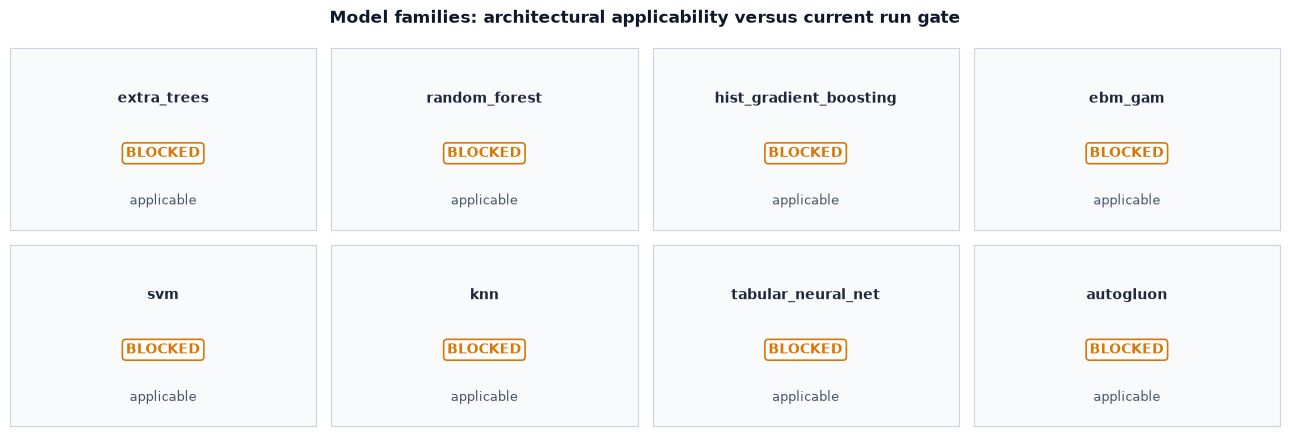

In [4]:
family_audit = pl.DataFrame([
    {'model_family': name,
     'applicable': bool(spec['applicable']),
     'execution_status': str(spec['execution_status']),
     'compatible_recipes': ', '.join(spec['compatible_recipes'] or []),
     'comparison_artifact': 'none \u2014 not run',
     'decision_reason': compact(spec['decision_reason'], 110)}
    for name, spec in campaign['model_family_audit'].items()
])
display(family_audit)
gate_distribution = (
    family_audit.group_by(['applicable', 'execution_status'])
    .agg(pl.len().alias('families'))
    .sort(['applicable', 'execution_status'])
)
display(gate_distribution)
silent_rejections = [
    name for name, spec in campaign['model_family_audit'].items()
    if not spec['applicable'] and not spec.get('rejection_reason')
]
if silent_rejections:
    raise ValueError(f'An inapplicable family must state its reason: {silent_rejections}')
if any(spec.get('oof_artifact') is not None for spec in campaign['model_family_audit'].values()):
    raise ValueError('No model family may reference a comparison artifact before execution')

show_figure(render_family_execution_tiles(
    [{'header': row['model_family'],
      'status': 'BLOCKED' if row['execution_status'] == 'blocked_unapproved_compute' else str(row['execution_status']).upper(),
      'meta': 'applicable' if row['applicable'] else 'not applicable'}
     for row in family_audit.to_dicts()],
    'Model families: architectural applicability versus current run gate'))


**Observation:** Every audited family is marked architecturally applicable and every one sits behind the same unapproved-compute gate. None references a comparison artifact.

**Interpretation:** The candidate space is currently limited by resourcing and dependency confirmation, not by structural incompatibility with the grouped evaluation. Nothing in this table asserts that any family is preferable — applicability is a precondition for comparison, not a result of one.

**Action:** Resolve dependency availability and the compute budget through the preflight step. Families whose dependencies remain unavailable after preflight should be re-recorded with a specific reason rather than being left indefinitely blocked.

## Finite experiment matrix

The matrix under `experiment_matrix` enumerates the design as a closed list: each row is one hypothesis with a stable identifier, the thing it varies, and an empty result. It is deliberately finite. The declared candidate count is a target, never a quota, and padding the list with near-duplicates to reach a number is prohibited.

### Two status axes, deliberately separate

| Field | Meaning | Changed by |
| --- | --- | --- |
| `status` | Design intent — is this hypothesis worth asking at all? (`planned`, `conditional`, `blocked`, `N/A`) | A design argument |
| `execution_status` | Run gate — is this row permitted to execute right now? | Preflight, approval, or a resolved safety review |

Keeping them apart prevents a common failure: a row that is intellectually worth running but currently ungated would otherwise be recorded as abandoned, and a row that is easy to run would otherwise look justified merely because it is cheap. A row's `execution_status` never runs ahead of its model family's gate.

### Rows that stay excluded

Prohibited and blocked rows remain in the matrix as visible, argued exclusions rather than deletions. `prohibited_opaque_building_id_digit_extraction` is closed permanently on reasoning grounds. `feat_group_aggregates_blocked` and `blocked_unverified_gte_family` are closed conditionally, pending point-in-time safety and provenance review respectively. Neither class of row is counted as available work, and neither is quietly dropped from the record.

**Purpose:** Render the finite experiment matrix from the campaign configuration and verify that no row advertises a runnable gate or carries a recorded outcome.

status,execution_status,rows
str,str,u32
"""N/A""","""prohibited""",1
"""blocked""","""blocked""",1
"""conditional""","""blocked""",1
"""planned""","""blocked_unapproved_compute""",18


id,status,execution_status,model_family,varies
str,str,str,str,str
"""feat_core_vs_provided""","""planned""","""blocked_unapproved_compute""","""hist_gradient_boosting""","""feature_set"""
"""feat_missingness_indicators""","""planned""","""blocked_unapproved_compute""","""hist_gradient_boosting""","""missingness_indicator_columns"""
"""feat_preserve_raw_vs_invalid_s…","""planned""","""blocked_unapproved_compute""","""hist_gradient_boosting""","""invalid_value_encoding"""
"""feat_categorical_interactions""","""planned""","""blocked_unapproved_compute""","""hist_gradient_boosting""","""categorical_interactions"""
"""feat_frequency_encoding""","""planned""","""blocked_unapproved_compute""","""hist_gradient_boosting""","""frequency_encoding"""
…,…,…,…,…
"""prohibited_opaque_building_id_…","""N/A""","""prohibited""","""not applicable""","""building_id_digit_features"""
"""blocked_unverified_gte_family""","""blocked""","""blocked""","""not applicable""","""gte_family_features"""
"""feat_missingness_passthrough_c…","""planned""","""blocked_unapproved_compute""","""hist_gradient_boosting""","""imputation_strategy"""


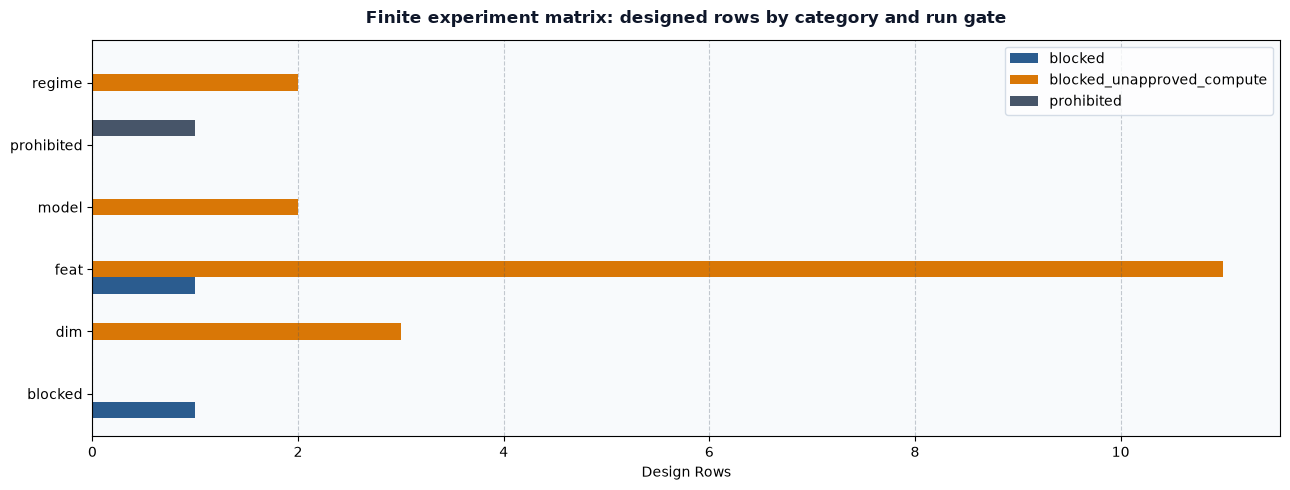

In [5]:
matrix_rows = campaign['experiment_matrix']
experiment_matrix = pl.DataFrame([
    {'id': str(row['id']),
     'status': str(row['status']),
     'execution_status': str(row['execution_status']),
     'model_family': 'not applicable' if row.get('model_family') is None else str(row['model_family']),
     'varies': str(row.get('varies')),
     'result': 'null \u2014 not run'}
    for row in matrix_rows
])
closed_gates = {'blocked', 'blocked_unapproved_compute', 'prohibited'}
runnable = experiment_matrix.filter(~pl.col('execution_status').is_in(list(closed_gates)))
if runnable.height:
    raise ValueError('No row may advertise a runnable gate while execution is unauthorized')
recorded_outcomes = [
    row['id'] for row in matrix_rows
    if row.get('result') is not None or row.get('oof_artifact') is not None
]
if recorded_outcomes:
    raise ValueError(f'Design-only rows must not carry outcomes: {recorded_outcomes}')
duplicate_ids = experiment_matrix.height - experiment_matrix.get_column('id').n_unique()
if duplicate_ids:
    raise ValueError('Experiment identifiers must be unique; padding is forbidden')
display(
    experiment_matrix.group_by(['status', 'execution_status'])
    .agg(pl.len().alias('rows'))
    .sort(['status', 'execution_status'])
)
display(experiment_matrix.select('id', 'status', 'execution_status', 'model_family', 'varies'))

matrix_category = (
    experiment_matrix
    .with_columns(pl.col('id').str.split('_').list.first().alias('category'))
    .group_by(['category', 'execution_status'])
    .agg(pl.len().alias('rows'))
)
show_figure(plot_experiment_status_bars(
    {category: {row['execution_status']: int(row['rows'])
                for row in matrix_category.filter(pl.col('category') == category).to_dicts()}
     for category in sorted(set(matrix_category.get_column('category').to_list()))},
    'Finite experiment matrix: designed rows by category and run gate'))


**Observation:** Every row carries a unique identifier, a null result, and a closed run gate; the excluded rows are present with their status recorded rather than removed.

**Interpretation:** The design intent is fully enumerated while the run gate stays uniformly shut. Because nothing has executed, the matrix expresses a set of questions and carries no information about their answers.

**Action:** Keep the matrix closed and argued. Add a row only when it asks a genuinely distinct question, and reopen a blocked row only by resolving its named blocker, never by relaxing the gate.

## Resource budget and stop rules

`configs/resource_budget.yaml` describes the general candidate campaign: its machine-dependent caps stay `null` pending preflight and explicit approval. The separate full baseline approval covers three baselines, four existing development folds, 12 fits, four CPU threads, and 45 minutes. Its RAM cap was removed by the user; peak RSS is reported, with no RAM limit enforced. It does not authorize FE, PCA, FS, HPO, or optional families. Measured baseline wall time, RSS, fit count, and budgets are copied from validated provenance above when available.

Guessing these caps before measurement would be worse than leaving them empty. A fabricated ceiling either blocks work that the host could easily absorb or authorises a run that exhausts it, and in both cases the number carries an authority it never earned. A `null` cap is an honest statement that the measurement has not happened.

### Stop rules

The stop rules are declarative constraints that must be checked programmatically before any fit, search trial, or campaign launch. In plain terms:

- No candidate-campaign execution while its caps or approval remain pending; the separately approved completed baseline run is reviewed above.
- The building-held-out development folds and the vault are preserved exactly as persisted.
- Row-wise or random-split fallback is forbidden outright.
- The candidate target is never padded to reach a number.
- No machine-dependent cap is set or enforced before preflight measurement is reviewed.

**Purpose:** Render candidate sizing, the pending resource caps, and the stop rules, and verify no machine-dependent cap has been set before preflight.

cap,value
str,str
"""maximum_cardinality""","""null — pending host preflight …"
"""max_ram_gb""","""null — pending host preflight …"
"""max_wall_time_seconds""","""null — pending host preflight …"
"""max_model_fits""","""null — pending host preflight …"
"""max_hpo_trials""","""null — pending host preflight …"
"""max_seed_count""","""null — pending host preflight …"


setting,value,meaning
str,i64,str
"""candidate_target""",100,"""design aspiration, never a quo…"
"""candidate_cap""",100,"""upper bound on distinct candid…"
"""designed matrix rows""",21,"""actual finite size; fewer is a…"


stop_rule,constraint
str,str
"""no_execution_while_caps_pendin…","""No full baseline, FE, FS, HPO,…"
"""preserve_grouped_folds_vault""","""The grouped building-held-out …"
"""no_row_wise_fallback""","""Row-wise or random-split fallb…"
"""never_pad_candidate_count""","""The candidate_target is a desi…"
"""no_machine_dependent_caps_befo…","""No machine-dependent resource …"


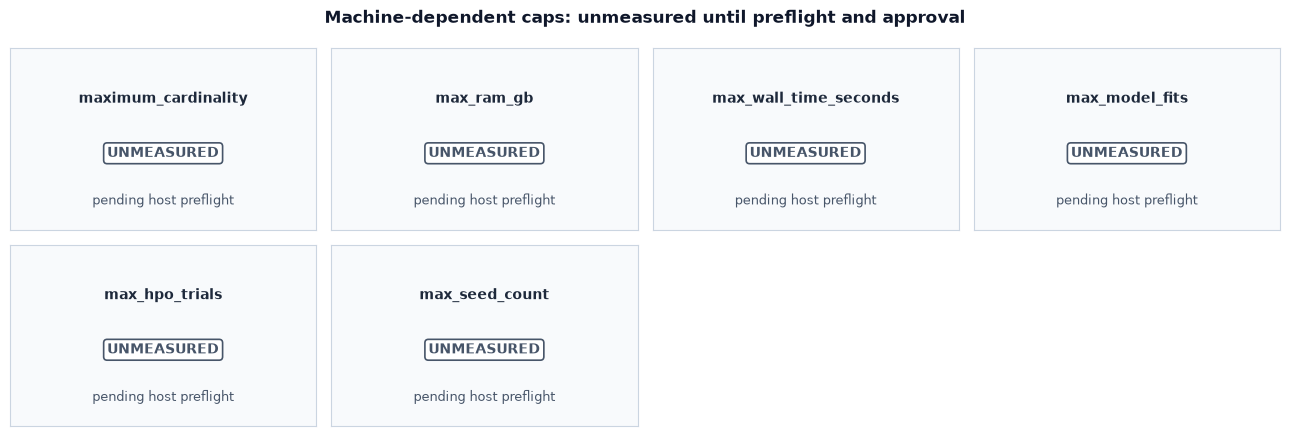

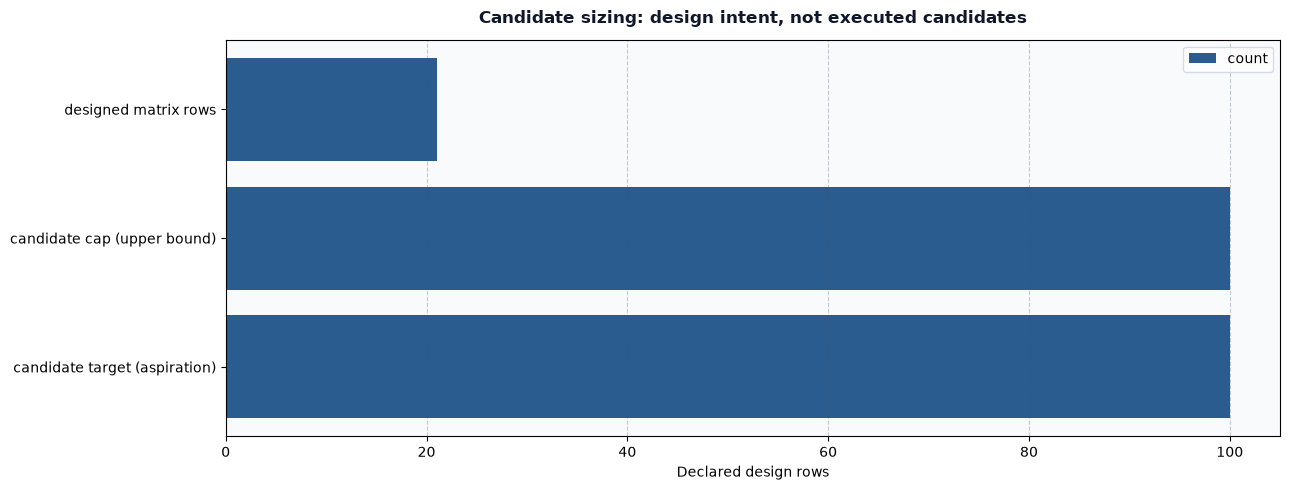

In [6]:
cap_keys = ('maximum_cardinality', 'max_ram_gb', 'max_wall_time_seconds',
            'max_model_fits', 'max_hpo_trials', 'max_seed_count')
premature_caps = [key for key in cap_keys if budget.get(key) is not None]
if premature_caps:
    raise ValueError(f'Machine-dependent caps must stay unset before preflight: {premature_caps}')
resource_caps = pl.DataFrame([
    {'cap': key,
     'value': 'null \u2014 pending host preflight and approval' if budget[key] is None else str(budget[key])}
    for key in cap_keys
])
display(resource_caps)
candidate_sizing = pl.DataFrame([
    {'setting': 'candidate_target', 'value': int(budget['candidate_target']),
     'meaning': 'design aspiration, never a quota'},
    {'setting': 'candidate_cap', 'value': int(budget['candidate_cap']),
     'meaning': 'upper bound on distinct candidates'},
    {'setting': 'designed matrix rows', 'value': experiment_matrix.height,
     'meaning': 'actual finite size; fewer is acceptable, padding is forbidden'},
])
display(candidate_sizing)
if experiment_matrix.height > int(budget['candidate_cap']):
    raise ValueError('The designed matrix exceeds the candidate cap')
stop_rules = pl.DataFrame([
    {'stop_rule': str(rule['id']), 'constraint': compact(rule['description'], 130)}
    for rule in budget['stop_rules']
])
display(stop_rules)

show_figure(render_unmeasured_cap_tiles(
    [{'header': row['cap'],
      'status': 'UNMEASURED' if budget[row['cap']] is None else 'SET',
      'meta': 'pending host preflight' if budget[row['cap']] is None else str(budget[row['cap']])}
     for row in resource_caps.to_dicts()],
    'Machine-dependent caps: unmeasured until preflight and approval'))
show_figure(plot_comparative_count_bars(
    {'candidate target (aspiration)': {'count': int(budget['candidate_target'])},
     'candidate cap (upper bound)': {'count': int(budget['candidate_cap'])},
     'designed matrix rows': {'count': int(experiment_matrix.height)}},
    'Candidate sizing: design intent, not executed candidates',
    xlabel='Declared design rows'))


**Observation:** Candidate sizing is set, every machine-dependent cap is null, both approval gates are pending, and the stop rules are recorded with explicit identifiers.

**Interpretation:** The budget describes a design that is ready to be measured, not a budget that has been measured. The stop rules are the mechanism that keeps that distinction enforceable rather than aspirational.

**Action:** Run the host preflight, record the measured caps, and obtain explicit approval before any gate opens. Until then the correct budget value is null, not an estimate.

## Smoke-test requirements

A smoke test is a cheap, deliberately tiny run whose only job is to prove the machinery is wired correctly before real resources are committed. It is not an experiment and produces no reportable outcome. Its value is that a broken fold loader, a misaligned feature frame, or a mis-specified metric is far cheaper to find on a handful of rows than partway through a full campaign.

### What must hold before any full candidate-campaign run

| Requirement | Why it must precede a full run |
| --- | --- |
| Host preflight recorded and reviewed | Resource caps cannot be enforced against unmeasured capacity |
| Explicit user approval recorded | Compute spend and run authorisation are the user's decision, not an inferred one |
| Campaign execution authorized | The configuration itself must stop declaring design-only mode |
| Persisted manifest loaded, never regenerated | A regenerated split silently changes the question and breaks comparability |
| Whole-building separation re-asserted at run time | The guarantee must hold in the execution path, not only in this review |
| Learned steps fitted inside training folds only | Any transform fitted across folds contaminates the validation estimate |
| Primary and guardrail metrics computed from the frozen contract | Metric drift between design and execution makes results incomparable |
| Every run writes its own comparison artifact | A number without a reproducible artifact cannot be audited or rechecked |

### Scope of the smoke run

The smoke run should exercise one fold, one baseline, and a truncated row sample — enough to touch every stage of the path from manifest to recorded artifact. Its outputs are diagnostic only and must never be presented as performance evidence or used to prefer one candidate over another.

**Purpose:** Render the execution preconditions with their current gate values and summarise the design state as a single reader-facing statement.

In [7]:
execution_preconditions = pl.DataFrame([
    {'requirement': 'host preflight recorded and reviewed',
     'gate_field': 'host_preflight_status', 'current_value': str(budget['host_preflight_status'])},
    {'requirement': 'explicit user approval recorded',
     'gate_field': 'user_approval_status', 'current_value': str(budget['user_approval_status'])},
    {'requirement': 'campaign execution authorized',
     'gate_field': 'campaign.execution_authorized', 'current_value': str(campaign['execution_authorized'])},
    {'requirement': 'resource caps measured, not guessed',
     'gate_field': 'resource caps', 'current_value': f'{len(cap_keys)} caps still null'},
    {'requirement': 'persisted manifest loaded, never regenerated',
     'gate_field': 'prediction_contract.split_manifest', 'current_value': str(contract['split_manifest'])},
    {'requirement': 'building-held-out folds preserved',
     'gate_field': 'prediction_contract.folds', 'current_value': str(contract['folds'])},
    {'requirement': 'metrics taken from the frozen contract',
     'gate_field': 'prediction_contract.primary_metric', 'current_value': str(contract['primary_metric'])},
])
display(execution_preconditions)
def pending_gate_names(gate_statuses: dict[str, str]) -> list[str]:
    return [
        name for name, status in gate_statuses.items()
        if str(status).casefold() != 'approved'
    ]
approval_statuses = {
    'host_preflight_status': budget['host_preflight_status'],
    'user_approval_status': budget['user_approval_status'],
}
open_gates = pending_gate_names(approval_statuses)
design_summary = (
    f'**Observation:** The design enumerates {experiment_matrix.height} finite experiment rows across '
    f'{family_audit.height} audited model families, anchored by {universal_baselines.height} universal '
    f'baselines and {context_baselines.height} context anchors. Every campaign result field is null and '
    f'{len(cap_keys)} machine-dependent caps remain unset; open approval gates: {len(open_gates)}.\n\n'
    '**Interpretation:** The candidate space is fully specified but remains unmeasured comparatively. '
    'No comparative campaign run has taken place; the earlier smoke verified workflow continuity only. '
    'The design supports no statement about relative merit, ordering, or preference among '
    'unexecuted campaign families or experiment rows. Baseline artifact status: '
    f"{baseline_review['status']}; eligible baseline metrics are reviewed separately above.\n\n"
    '**Action:** Complete the host preflight, record measured caps, obtain explicit approval, then pass the '
    'smoke checks before any full candidate-campaign run. FE, PCA, FS and HPO remain not run.'
)
display(Markdown(design_summary))

requirement,gate_field,current_value
str,str,str
"""host preflight recorded and re…","""host_preflight_status""","""pending"""
"""explicit user approval recorde…","""user_approval_status""","""pending"""
"""campaign execution authorized""","""campaign.execution_authorized""","""False"""
"""resource caps measured, not gu…","""resource caps""","""6 caps still null"""
"""persisted manifest loaded, nev…","""prediction_contract.split_mani…","""outputs/splits/building_folds_…"
"""building-held-out folds preser…","""prediction_contract.folds""","""4"""
"""metrics taken from the frozen …","""prediction_contract.primary_me…","""roc_auc"""


**Observation:** The design enumerates 21 finite experiment rows across 8 audited model families, anchored by 3 universal baselines and 4 context anchors. Every campaign result field is null and 6 machine-dependent caps remain unset; open approval gates: 2.

**Interpretation:** The candidate space is fully specified but remains unmeasured comparatively. No comparative campaign run has taken place; the earlier smoke verified workflow continuity only. The design supports no statement about relative merit, ordering, or preference among unexecuted campaign families or experiment rows. Baseline artifact status: completed; eligible baseline metrics are reviewed separately above.

**Action:** Complete the host preflight, record measured caps, obtain explicit approval, then pass the smoke checks before any full candidate-campaign run. FE, PCA, FS and HPO remain not run.